# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 24)
Train: 947 | Val: 229 | Test: 567


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 3.42e-04 | train loss 1.1409 acc 0.369 | val loss 1.0928 acc 0.467 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 3.42e-04 | train loss 1.0985 acc 0.422 | val loss 1.0381 acc 0.533 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 3.42e-04 | train loss 1.0804 acc 0.477 | val loss 1.0211 acc 0.594 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 3.42e-04 | train loss 1.0349 acc 0.556 | val loss 1.1531 acc 0.537


...

[ResNet-18 (scratch)] Epoch  22/100 | LR: 3.42e-04 | train loss 0.8876 acc 0.615 | val loss 1.1066 acc 0.555


[ResNet-18 (scratch)] Epoch  23/100 | LR: 3.42e-04 | train loss 0.9050 acc 0.585 | val loss 0.8814 acc 0.651


[ResNet-18 (scratch)] Epoch  24/100 | LR: 3.42e-04 | train loss 0.8736 acc 0.620 | val loss 0.8203 acc 0.655


[ResNet-18 (scratch)] Epoch  25/100 | LR: 3.42e-04 | train loss 0.8762 acc 0.619 | val loss 0.8196 acc 0.638


[ResNet-18 (scratch)] Epoch  26/100 | LR: 3.42e-04 | train loss 0.8525 acc 0.639 | val loss 0.8487 acc 0.638

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 26.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.8012)


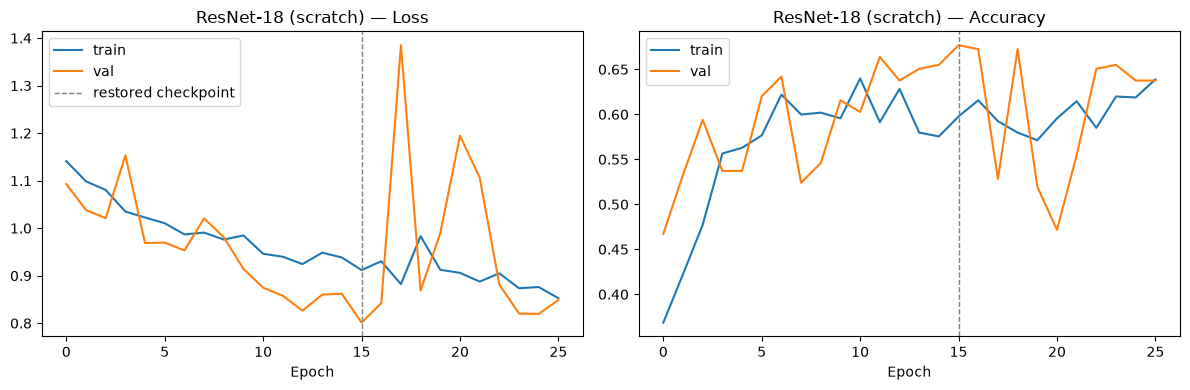

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.824


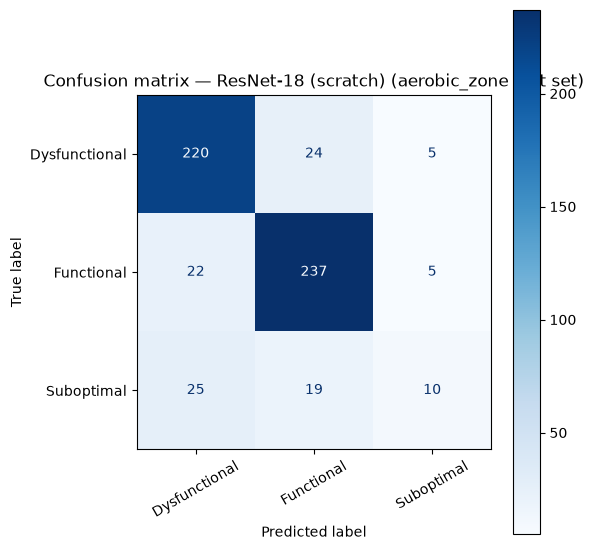

               precision    recall  f1-score   support

Dysfunctional      0.824     0.884     0.853       249
   Functional      0.846     0.898     0.871       264
   Suboptimal      0.500     0.185     0.270        54

     accuracy                          0.824       567
    macro avg      0.723     0.655     0.665       567
 weighted avg      0.804     0.824     0.806       567



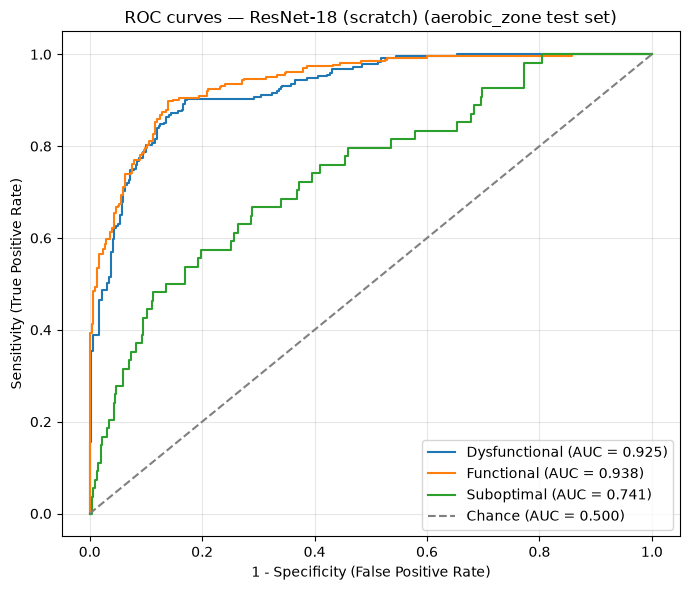

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.925
  Functional     : 0.938
  Suboptimal     : 0.741

Mean AUC (over 3/3 classes with test examples): 0.868


(np.float64(0.8236331569664903),
 {'Dysfunctional': 0.9253365663913516,
  'Functional': 0.9383688368836883,
  'Suboptimal': 0.7412822178904049})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_resnet18_scratch_chronological.pkl
Saved model weights to ../models/pad/aerobic_zone_aug/aerobic_zone_resnet18_scratch_chronological.pt
